# Method 2 — Time-Series (Owner: Member B)

**Goal:** classify each skill as rising/stable/declining and forecast the top skills.

**Data:** Google Trends, India, `today 5-y` (weekly), 20 skills. Skills are queried by Google Trends
**topic ID** where that gave a clean series (e.g. Python → "Programming language", Java → the language, not
the island); IDs are in `config/review2_skills.json` under `trends_queries`. **AWS uses the plain term**
because its company topic had a coverage gap (≈0 until mid-2022, then a step to ≈19), which produced a fake
"+103% rising" result. Every batch carries the shared `SQL` anchor, and `scripts/rescale_trends.py` aligns
the batches into `data/processed/trends_rescaled_IN.csv`.

**Writes (contract output):**
- `data/review2/skill_trends.csv` — columns: `skill, slope_per_week, pct_change, class, low_volume, mk_p,
  trend_confirmed` (the last two are the Mann-Kendall p-value and whether it confirms the class; see 2d)
- figures to `reports/time_series/`

**`low_volume` flag:** Google reports integers 0–100. A series is flagged when its first- or last-year
level is below 5 (one rounding step is then ≥20% of the value, larger than our ±10% class cut-off) or when
it has more than 5 zero weeks (a coverage gap). Flagged skills keep their computed class but must not be
presented as findings.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
cfg = json.load(open(ROOT / "config" / "review2_skills.json"))
anchor, skills = cfg["anchor"], cfg["skills"]

# Rescaled, anchor-aligned weekly series produced by scripts/rescale_trends.py
trends = pd.read_csv(ROOT / "data" / "processed" / "trends_rescaled_IN.csv", parse_dates=["date"])
trends = trends.set_index("date").sort_index()
FIG = ROOT / "reports" / "time_series"
FIG.mkdir(parents=True, exist_ok=True)
print(f"anchor={anchor} | {trends.shape[1]} skills | {len(trends)} weeks "
      f"({trends.index.min().date()} to {trends.index.max().date()})")
trends.tail(3)

anchor=SQL | 20 skills | 261 weeks (2021-10-10 to 2026-10-04)


,SQL,AWS,Python,Machine Learning,Azure,SEO,Kubernetes,Google Cloud,SAP,Java,Spark,Power BI,Linux,Excel,React,Docker,Tableau,Deep Learning,JavaScript,Git
date,,,,,,,,,,,,,,,,,,,,
2026-09-20,16.0,15.0,44.0,11.0,8.0,5.7335,1.911167,5.733500,1.911167,29.191440,0.973048,4.86524,15.568768,55.498586,6.937323,3.964185,0.991046,1.764879,12.942444,7.647808
2026-09-27,14.0,14.0,39.0,10.0,6.0,5.7335,1.911167,5.733500,0.955583,26.272296,0.973048,4.86524,12.649624,58.471725,5.946277,3.964185,0.991046,1.764879,11.765858,7.647808
2026-10-04,16.0,16.0,45.0,10.0,8.0,5.7335,1.911167,6.689083,0.955583,31.137536,0.973048,4.86524,13.622672,71.355325,6.937323,3.964185,0.991046,1.764879,13.530736,8.824393


## 1. Clean & smooth the weekly series

The series are already anchor-rescaled (comparable across batches). We apply an 8-week moving average
to separate the underlying trend from weekly noise before plotting.

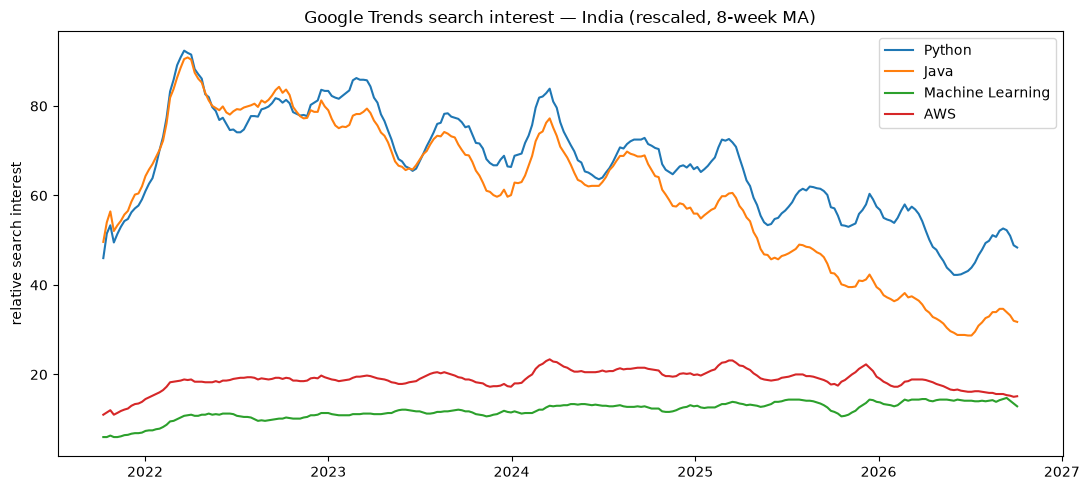

In [2]:
smoothed = trends.rolling(8, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(11, 5))
for s in ["Python", "Java", "Machine Learning", "AWS"]:
    ax.plot(smoothed.index, smoothed[s], label=s)
ax.set_title("Google Trends search interest — India (rescaled, 8-week MA)")
ax.set_ylabel("relative search interest")
ax.legend()
plt.tight_layout()
fig.savefig(FIG / "01_trend_lines.png", dpi=120)
plt.show()

## 2. Classify rising / stable / declining

For each skill we fit a linear slope over the 5 years and compare the **median** of the last year to the
median of the first year (median, so a single viral week cannot decide the class). Label: **rising**
(≥ +10%), **declining** (≤ −10%), else **stable**.

In [3]:
LOW_VOLUME_LEVEL = 5   # fixed a priori: below this, one integer rounding step is >=20% of the value
MAX_ZERO_WEEKS = 5     # a topic that is 0 for many weeks has a coverage gap, not a real trend

def classify(series: pd.Series):
    y = series.values.astype(float)
    weeks = np.arange(len(y))
    slope = float(np.polyfit(weeks, y, 1)[0])
    # Median, not mean: a single viral week (e.g. SEO, Dec 2025) must not decide the class.
    first, last = np.median(y[:52]), np.median(y[-52:])
    pct = float(100 * (last - first) / first) if first else 0.0
    cls = "rising" if pct >= 10 else "declining" if pct <= -10 else "stable"
    low = bool(min(first, last) < LOW_VOLUME_LEVEL or (y < 0.5).sum() > MAX_ZERO_WEEKS)
    return slope, pct, cls, low

rows = []
for s in trends.columns:
    slope, pct, cls, low = classify(trends[s])
    rows.append({"skill": s, "slope_per_week": round(slope, 4),
                 "pct_change": round(pct, 2), "class": cls, "low_volume": low})
trend_tbl = pd.DataFrame(rows).sort_values("pct_change", ascending=False).reset_index(drop=True)
trend_tbl

,skill,slope_per_week,pct_change,class,low_volume
0,Deep Learning,0.0048,66.67,rising,True
1,Google Cloud,0.0112,50.00,rising,True
2,Machine Learning,0.0199,40.00,rising,False
3,Excel,0.0284,1.38,stable,False
4,Power BI,0.0042,0.00,stable,False
5,Docker,0.0014,0.00,stable,False
6,SEO,0.0129,0.00,stable,False
7,AWS,0.0026,-5.56,stable,False
8,Azure,-0.0050,-16.67,declining,False
9,Kubernetes,-0.0020,-25.00,declining,True


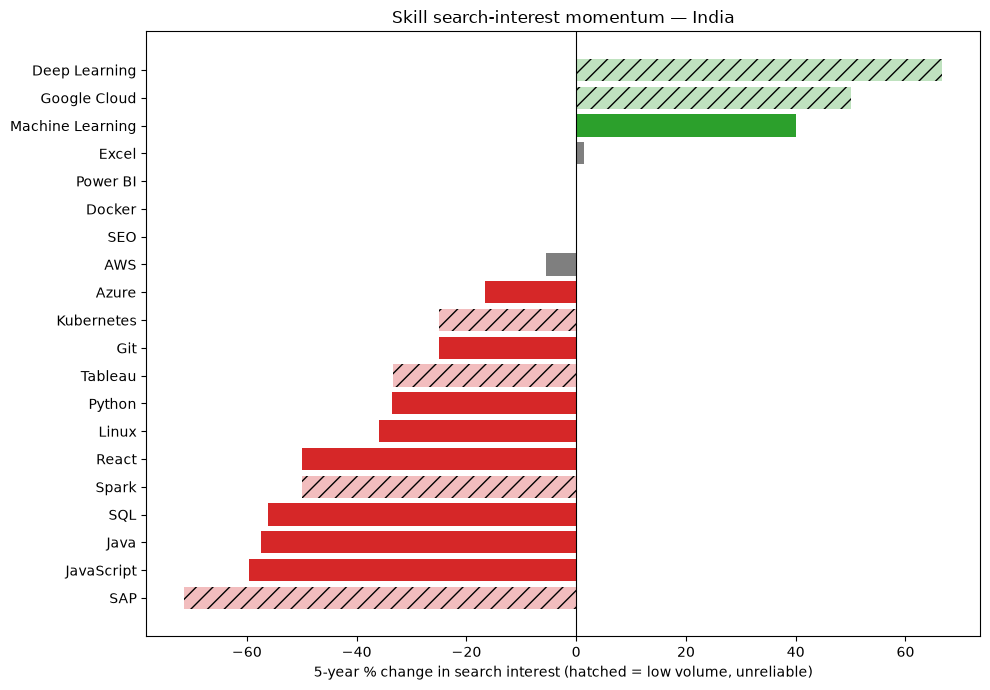

In [4]:
colors = {"rising": "tab:green", "stable": "tab:gray", "declining": "tab:red"}
fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(trend_tbl["skill"], trend_tbl["pct_change"],
               color=[colors[c] for c in trend_tbl["class"]])
for bar, low in zip(bars, trend_tbl["low_volume"]):
    if low:
        bar.set_alpha(0.3)
        bar.set_hatch("//")
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("5-year % change in search interest (hatched = low volume, unreliable)")
ax.set_title("Skill search-interest momentum — India")
ax.invert_yaxis()
plt.tight_layout()
fig.savefig(FIG / "02_momentum.png", dpi=120)
plt.show()

## 2b. Autocorrelation (ACF / PACF)

Before forecasting we inspect the **autocorrelation**. The ACF/PACF of the differenced series show how a
value relates to its own past — this is what justifies the AR and MA orders in ARIMA (syllabus:
*Autocorrelation and ARIMA Models*).

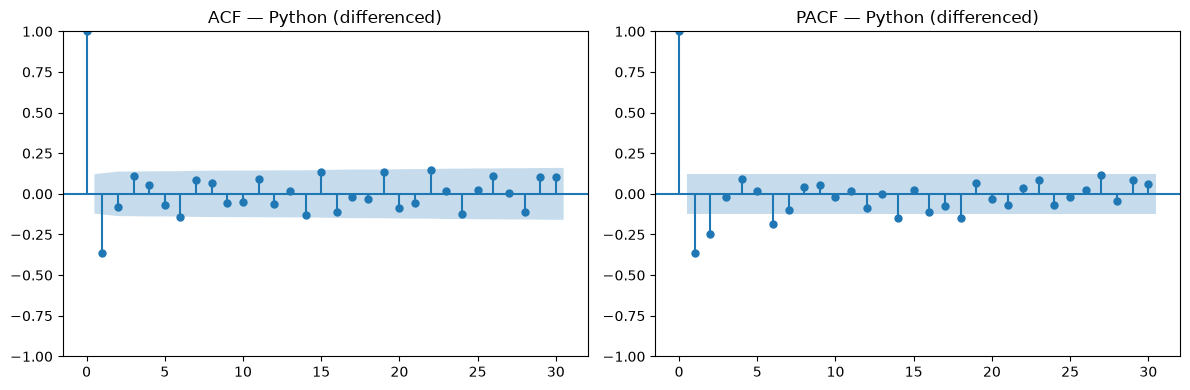

In [5]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

acf_skill = "Python"
series = trends[acf_skill].astype(float)
diff = series.diff().dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(diff, ax=axes[0], lags=30)
plot_pacf(diff, ax=axes[1], lags=30, method="ywm")
axes[0].set_title(f"ACF — {acf_skill} (differenced)")
axes[1].set_title(f"PACF — {acf_skill} (differenced)")
plt.tight_layout()
fig.savefig(FIG / "04_acf_pacf.png", dpi=120)
plt.show()

## 2c. Data validation of the Trends series

Before trusting any trend we validate the data itself: completeness, anchor consistency across batches,
and agreement between independent pulls. The Trends API returns a *sample*, and query wording matters, so
we compare our two complete pulls: **2026-10-15** (plain-word queries, an earlier skill list with different
batch groupings) and **2026-10-16** (Google topic IDs; the pull analysed here). For the skills present in
both, agreement means the class does not depend on query wording, batch grouping or Google's sampling;
a disagreement flags a term whose plain word is ambiguous (exactly what the topic IDs were meant to fix).

The anchor criterion was fixed before running: correlation between batches ≥ 0.95. Cross-pull agreement is
reported as a number, not pass/fail, because some disagreement is expected for ambiguous plain words.

In [6]:
import glob
import sys

sys.path.insert(0, str(ROOT / 'scripts'))
from rescale_trends import rescale_pull, pull_date, load_batch

raw_paths = sorted(glob.glob(str(ROOT / 'data' / 'raw' / 'trends' / 'trends_IN_batch*.csv')))
pull_a, pull_b = '2026-10-15', '2026-10-16'   # two complete pulls; pull_b is the one analysed
by_pull = {d: [p for p in raw_paths if pull_date(p) == d] for d in (pull_a, pull_b)}
rescaled = {d: rescale_pull(ps) for d, ps in by_pull.items()}

checks = []
gaps = trends.index.to_series().diff().dropna().dt.days
checks.append(('Regular weekly grid', bool((gaps == 7).all()),
               f'{len(trends)} weeks, gaps = {sorted(gaps.unique())} days'))
checks.append(('No missing values', bool(trends.notna().all().all()),
               f'{int(trends.isna().sum().sum())} NaN'))
checks.append(('No negative values', bool((trends >= 0).all().all()), f'min = {trends.min().min():.2f}'))
checks.append(('All frozen skills present', set(skills) == set(trends.columns), f'{len(skills)} skills'))

# Anchor: the same term (SQL) is in every batch, so its raw series must agree across batches.
anc = pd.DataFrame({Path(p).stem.split('_')[2]: load_batch(p)[anchor].astype(float)
                    for p in by_pull[pull_b]})
anc_r = anc.corrwith(anc.iloc[:, 0])
factors = anc.mean() / anc.mean().iloc[0]
checks.append(('Anchor agrees across batches (min r with batch01 >= 0.95)', bool(anc_r.min() >= 0.95),
               f'min r = {anc_r.min():.3f}; batch scale factors {factors.min():.2f}-{factors.max():.2f}'))

# Cross-pull agreement on the skills both pulls contain (plain-word vs topic-ID queries).
common = rescaled[pull_a].index.intersection(rescaled[pull_b].index)
shared = [s for s in skills if s in rescaled[pull_a].columns]
rep = []
for s in shared:
    a, b = rescaled[pull_a].loc[common, s], rescaled[pull_b].loc[common, s]
    _, pa, ca, _ = classify(a)
    _, pb, cb, _ = classify(b)
    rep.append({'skill': s, 'r_between_pulls': round(a.corr(b), 3), 'pct_pull_a': round(pa, 1),
                'pct_pull_b': round(pb, 1), 'class_pull_a': ca, 'class_pull_b': cb, 'same_class': ca == cb})
repro = pd.DataFrame(rep)
checks.append(('Class agrees across the two pulls (informational)', 'n/a',
               f'{int(repro["same_class"].sum())}/{len(repro)} shared skills; median r = {repro["r_between_pulls"].median():.3f}'))

val = pd.DataFrame(checks, columns=['check', 'passed', 'detail'])
val.to_csv(FIG / 'validation_checks.csv', index=False)
repro.to_csv(FIG / 'pull_reproducibility.csv', index=False)
display(val)
repro.sort_values('r_between_pulls')

,check,passed,detail
0,Regular weekly grid,True,"261 weeks, gaps = [np.int64(7)] days"
1,No missing values,True,0 NaN
2,No negative values,True,min = 0.00
3,All frozen skills present,True,20 skills
4,Anchor agrees across batches (min r with batch...,True,min r = 0.999; batch scale factors 1.00-1.70
5,Class agrees across the two pulls (informational),n/a,10/14 shared skills; median r = 0.956


,skill,r_between_pulls,pct_pull_a,pct_pull_b,class_pull_a,class_pull_b,same_class
10,Spark,-0.308,16.7,-50.0,rising,declining,False
8,SAP,-0.060,-3.1,-71.4,stable,declining,False
3,Machine Learning,0.500,0.0,40.0,stable,rising,False
7,Google Cloud,0.777,66.7,50.0,rising,rising,True
6,Kubernetes,0.805,-33.3,-25.0,declining,declining,True
11,Power BI,0.939,0.0,0.0,stable,stable,True
4,Azure,0.944,-21.4,-16.7,declining,declining,True
13,Excel,0.967,-2.1,1.4,stable,stable,True
0,AWS,0.970,-10.0,-5.6,declining,stable,False
12,Linux,0.974,-31.8,-36.0,declining,declining,True


## 2d. Statistical validation of the labels (Mann-Kendall) + threshold sensitivity

The ±10% rule is a heuristic. We test each skill's monthly series with the **Mann-Kendall trend test**
(Hamed-Rao variant, which corrects for the autocorrelation we saw in the ACF) and report **Sen's slope**.

- `trend_confirmed` = for rising/declining: the test is significant (p < 0.05) in the same direction;
  for stable: the test finds no significant trend.
- We then re-label at ±5/10/15/20% to see which classes depend on our arbitrary cut-off.

In [7]:
import pymannkendall as mk

weeks_in_month = trends.resample('MS').size()
monthly = trends.resample('MS').mean()[weeks_in_month >= 4]  # drop partial first/last months

mk_rows = []
for s in trends.columns:
    r = mk.hamed_rao_modification_test(monthly[s].values)
    mk_rows.append({'skill': s, 'mk_trend': r.trend, 'mk_p': float(r.p), 'sen_slope_per_month': float(r.slope)})
mk_tbl = pd.DataFrame(mk_rows)

label_check = trend_tbl.merge(mk_tbl, on='skill')
direction = {'rising': 'increasing', 'declining': 'decreasing'}

def confirmed(row):
    significant = row['mk_p'] < 0.05
    if row['class'] == 'stable':
        return not significant
    return bool(significant and row['mk_trend'] == direction[row['class']])

label_check['trend_confirmed'] = label_check.apply(confirmed, axis=1)
label_check['mk_p'] = label_check['mk_p'].round(4)
label_check['sen_slope_per_month'] = label_check['sen_slope_per_month'].round(3)
label_check.to_csv(FIG / 'label_validation.csv', index=False)

reliable_lc = label_check[~label_check['low_volume']]
print(f'reliable skills with label confirmed by Mann-Kendall: '
      f'{int(reliable_lc["trend_confirmed"].sum())}/{len(reliable_lc)}')
display(reliable_lc[['skill', 'class', 'pct_change', 'mk_trend', 'mk_p', 'sen_slope_per_month', 'trend_confirmed']])

# Threshold sensitivity: which labels would flip if the cut-off were different?
sens = pd.DataFrame({'skill': trend_tbl['skill'], 'low_volume': trend_tbl['low_volume']})
for thr in (5, 10, 15, 20):
    sens[f'{thr}%'] = trend_tbl['pct_change'].apply(
        lambda p: 'rising' if p >= thr else 'declining' if p <= -thr else 'stable')
unstable = sens[(~sens['low_volume']) & (sens[['5%', '10%', '15%', '20%']].nunique(axis=1) > 1)]
print(f'\nreliable skills whose class changes with the cut-off: {len(unstable)}')
unstable.drop(columns='low_volume')

reliable skills with label confirmed by Mann-Kendall: 11/14


,skill,class,pct_change,mk_trend,mk_p,sen_slope_per_month,trend_confirmed
2,Machine Learning,rising,40.00,increasing,0.0000,0.082,True
3,Excel,stable,1.38,no trend,0.4080,0.147,True
4,Power BI,stable,0.00,no trend,0.4904,0.025,True
5,Docker,stable,0.00,no trend,0.9277,0.000,True
6,SEO,stable,0.00,increasing,0.0007,0.013,False
7,AWS,stable,-5.56,no trend,0.8757,0.003,True
8,Azure,declining,-16.67,no trend,0.5560,-0.019,False
10,Git,declining,-25.00,decreasing,0.0020,-0.049,True
12,Python,declining,-33.55,decreasing,0.0000,-0.591,True
13,Linux,declining,-36.00,decreasing,0.0000,-0.160,True



reliable skills whose class changes with the cut-off: 2


,skill,5%,10%,15%,20%
7,AWS,declining,stable,stable,stable
8,Azure,declining,declining,declining,stable


## 3. Forecast top skills (ARIMA) + evaluate (MAPE vs naïve)

We hold out the last 6 complete months, fit an ARIMA(1,1,1) on the rest, and compare forecast error
(MAPE) against a naïve last-value baseline. A useful model beats the naïve baseline. This single split is
a first look only; section 3c repeats the comparison over many forecast origins.

forecast skills: ['Excel', 'Python', 'Java', 'JavaScript']


C:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\

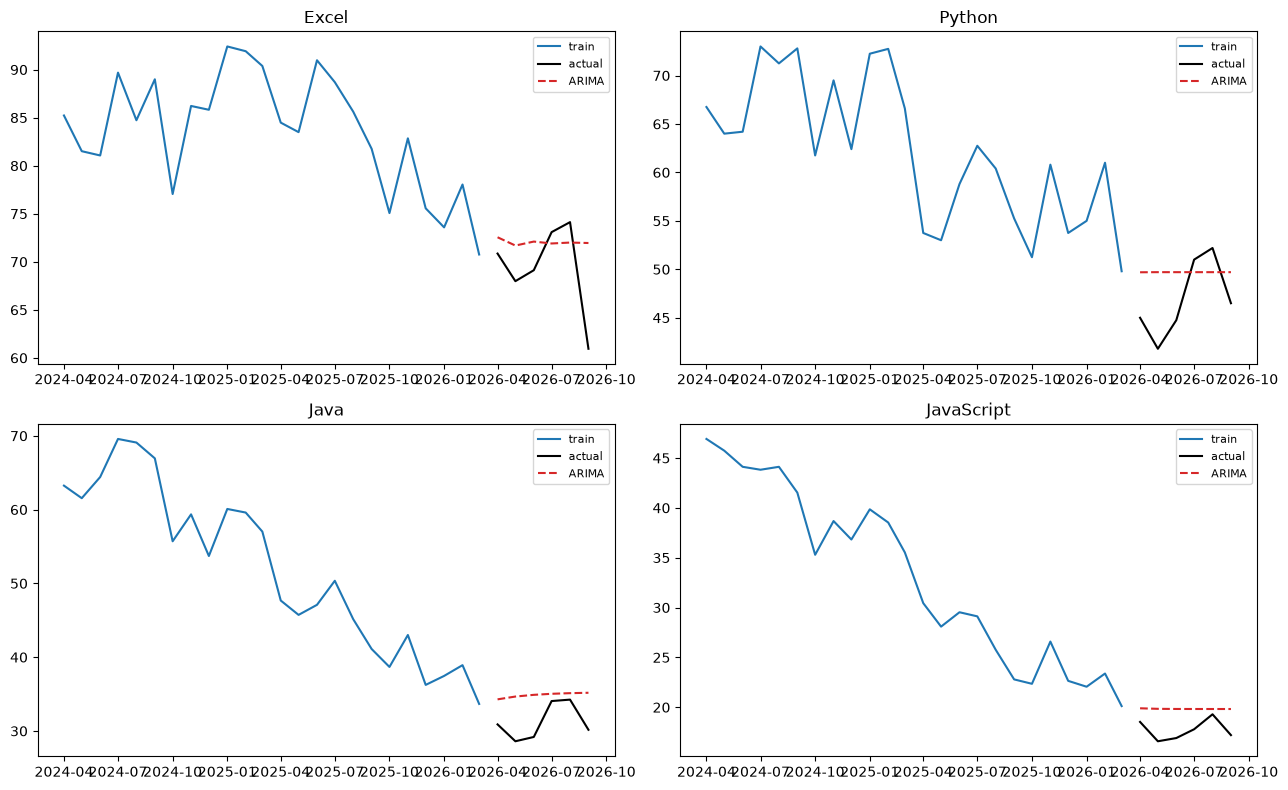

,skill,arima_mape,naive_mape,winner
0,Excel,5.78,5.07,naive
1,Python,9.11,9.19,ARIMA
2,Java,12.30,9.41,naive
3,JavaScript,12.27,13.84,ARIMA


In [8]:
from statsmodels.tsa.arima.model import ARIMA

def mape(actual, pred):
    actual, pred = np.asarray(actual, float), np.asarray(pred, float)
    mask = actual != 0
    return float(100 * np.mean(np.abs((actual[mask] - pred[mask]) / actual[mask])))

# Weekly search data is noisy and close to a random walk at short horizons, so we forecast on
# monthly means where the underlying trend is clearer (a standard aggregation choice).
weeks_in_month = trends.resample("MS").size()
monthly = trends.resample("MS").mean()[weeks_in_month >= 4]  # drop partial first/last months
horizon = 6  # months held out

# Selection rule fixed in advance: the 4 highest-volume skills that are not low_volume.
reliable = trend_tbl.loc[~trend_tbl["low_volume"], "skill"]
forecast_skills = monthly[reliable].mean().nlargest(4).index.tolist()
print("forecast skills:", forecast_skills)

results = []
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, s in zip(axes.ravel(), forecast_skills):
    y = monthly[s].astype(float)
    train, test = y.iloc[:-horizon], y.iloc[-horizon:]
    fc = ARIMA(train, order=(1, 1, 1)).fit().forecast(horizon)
    naive = np.repeat(train.iloc[-1], horizon)
    results.append({"skill": s, "arima_mape": round(mape(test, fc), 2),
                    "naive_mape": round(mape(test, naive), 2)})
    ax.plot(train.index[-24:], train.iloc[-24:], label="train")
    ax.plot(test.index, test, color="black", label="actual")
    ax.plot(test.index, fc, color="tab:red", ls="--", label="ARIMA")
    ax.set_title(s)
    ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(FIG / "03_forecasts.png", dpi=120)
plt.show()

res = pd.DataFrame(results)
res["winner"] = np.where(res["arima_mape"] <= res["naive_mape"], "ARIMA", "naive")
res

## 3b. Compare forecasting methods (syllabus coverage)

We benchmark four methods on the same 6-month holdout, by MAPE:
- **Naïve** (last value) — baseline
- **Simple Exponential Smoothing** — weights recent points more
- **ARIMA(1,1,1)** — autocorrelation-based
- **Holt-Winters** — a model with **trend + seasonality** (12-month)

The lowest MAPE per skill wins.

In [9]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing

def all_forecasts(train, horizon):
    f = {"naive": np.repeat(train.iloc[-1], horizon)}
    f["ses"] = SimpleExpSmoothing(train, initialization_method="estimated").fit().forecast(horizon)
    f["arima"] = ARIMA(train, order=(1, 1, 1)).fit().forecast(horizon)
    try:
        hw = ExponentialSmoothing(train, trend="add", seasonal="add", seasonal_periods=12,
                                  initialization_method="estimated").fit()
        f["holt_winters"] = hw.forecast(horizon)
    except Exception:
        f["holt_winters"] = np.full(horizon, np.nan)
    return f

comparison = []
for s in forecast_skills:
    y = monthly[s].astype(float)
    train, test = y.iloc[:-horizon], y.iloc[-horizon:]
    row = {"skill": s}
    for name, pred in all_forecasts(train, horizon).items():
        row[name] = round(mape(test, pred), 2)
    comparison.append(row)

comp = pd.DataFrame(comparison)
methods = ["naive", "ses", "arima", "holt_winters"]
comp["best"] = comp[methods].idxmin(axis=1)
comp

C:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\

C:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


,skill,naive,ses,arima,holt_winters,best
0,Excel,5.07,5.84,5.78,5.19,naive
1,Python,9.19,9.19,9.11,13.16,arima
2,Java,9.41,9.53,12.30,17.18,naive
3,JavaScript,13.84,13.84,12.27,18.59,arima


## 3c. Rolling-origin backtest (replaces reliance on a single split)

One 6-month holdout on four skills can be lucky or unlucky. Here every reliable (non-`low_volume`) skill is
forecast **3 months ahead from 7 different origins** (every 3 months over the most recent ~21 months), using
only data available at each origin (expanding window). We compare Naïve, Simple Exponential Smoothing,
ARIMA(1,1,1) and Holt-Winters by MAPE, count how often each beats naïve, and test the difference with a
Wilcoxon signed-rank test (indicative only: windows of one skill overlap in time).

C:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\

C:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


C:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


C:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


C:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


...

C:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


C:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\

14 skills x 7 origins x horizon 3 months = 98 forecast windows


C:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\ramakrishanu\Documents\anusanth\ba\project\Career-Market-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


,mean_mape,median_mape,mean_smape,mean_mase,median_mase,mase_vs_naive,beats_naive_share,wilcoxon_p_vs_naive
model,,,,,,,,
naive,15.878,10.720,13.533,1.623,1.035,1.000,NaN,NaN
ses,15.683,10.585,13.235,1.574,1.076,0.969,0.49,0.877
arima,17.759,11.059,13.285,1.697,1.126,1.045,0.51,0.800
holt_winters,21.063,12.207,14.902,1.936,1.115,1.193,0.48,0.398


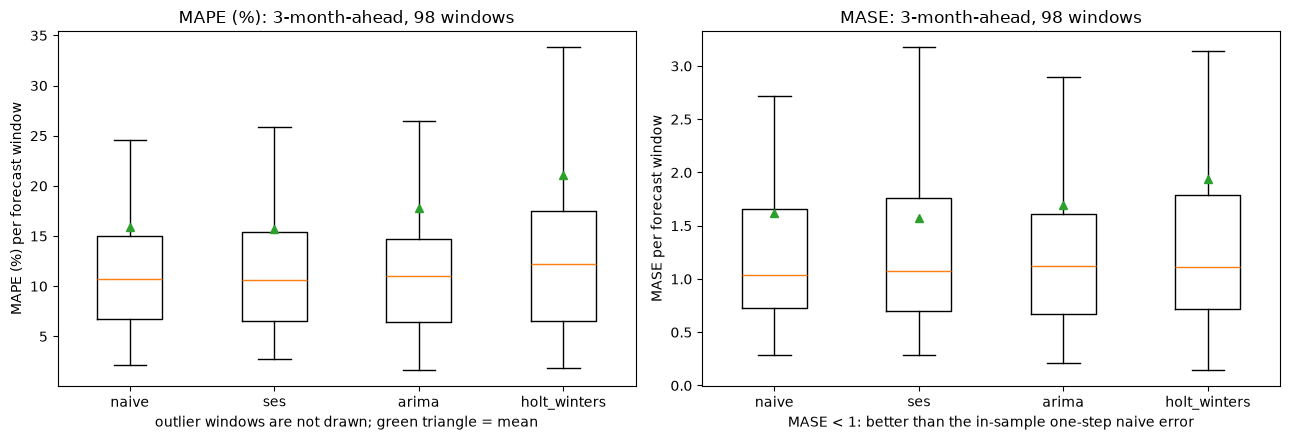

model,naive,ses,arima,holt_winters,best
skill,,,,,
AWS,10.65,10.01,10.45,10.13,ses
Azure,11.47,11.52,12.95,10.92,holt_winters
Docker,15.96,16.44,13.99,13.87,holt_winters
Excel,5.62,5.89,5.88,7.94,naive
Git,10.67,10.56,10.85,8.53,holt_winters
Java,11.10,11.16,11.60,13.17,naive
JavaScript,10.85,10.85,10.46,16.71,arima
Linux,10.12,10.12,9.66,13.62,arima
Machine Learning,8.58,7.31,7.80,8.71,ses


In [10]:
from scipy.stats import wilcoxon

H, STEP, N_ORIGINS = 3, 3, 7
reliable_skills = trend_tbl.loc[~trend_tbl['low_volume'], 'skill'].tolist()
MODELS = ['naive', 'ses', 'arima', 'holt_winters']

def smape(actual, pred):
    a, p = np.asarray(actual, float), np.asarray(pred, float)
    return float(100 * np.mean(2 * np.abs(a - p) / (np.abs(a) + np.abs(p))))

def mase(actual, pred, train):
    # Scaled by the in-sample one-step naive error, so MASE < 1 means better than that naive benchmark.
    scale = np.mean(np.abs(np.diff(np.asarray(train, float))))
    return float(np.mean(np.abs(np.asarray(actual, float) - np.asarray(pred, float))) / scale)

bt = []
for s in reliable_skills:
    y = monthly[s].astype(float)
    last_origin = len(y) - H
    for t in range(last_origin - STEP * (N_ORIGINS - 1), last_origin + 1, STEP):
        train, test = y.iloc[:t], y.iloc[t:t + H]
        for name, pred in all_forecasts(train, H).items():
            bt.append({'skill': s, 'origin': train.index[-1].strftime('%Y-%m'), 'model': name,
                       'mape': mape(test, pred), 'smape': smape(test, pred), 'mase': mase(test, pred, train)})
bt = pd.DataFrame(bt)
piv = bt.pivot_table(index=['skill', 'origin'], columns='model', values='mape')[MODELS]
piv_smape = bt.pivot_table(index=['skill', 'origin'], columns='model', values='smape')[MODELS]
piv_mase = bt.pivot_table(index=['skill', 'origin'], columns='model', values='mase')[MODELS]

summary = pd.DataFrame({'mean_mape': piv.mean(), 'median_mape': piv.median(),
                        'mean_smape': piv_smape.mean(), 'mean_mase': piv_mase.mean(),
                        'median_mase': piv_mase.median()})
summary['mase_vs_naive'] = summary['mean_mase'] / summary.loc['naive', 'mean_mase']  # <1 = beats naive
for m in MODELS[1:]:
    valid = piv[m].notna()
    summary.loc[m, 'beats_naive_share'] = float((piv.loc[valid, m] < piv.loc[valid, 'naive']).mean())
    d = (piv[m] - piv['naive']).dropna()
    summary.loc[m, 'wilcoxon_p_vs_naive'] = float(wilcoxon(d).pvalue) if (d != 0).any() else np.nan
summary = summary.round(3)
summary.to_csv(FIG / 'rolling_backtest_summary.csv')
print(f'{len(reliable_skills)} skills x {N_ORIGINS} origins x horizon {H} months = {len(piv)} forecast windows')
display(summary)

per_skill = piv.groupby('skill').mean().round(2)
per_skill['best'] = per_skill[MODELS].idxmin(axis=1)
per_skill.to_csv(FIG / 'rolling_backtest_per_skill.csv')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, data, name in ((axes[0], piv, 'MAPE (%)'), (axes[1], piv_mase, 'MASE')):
    ax.boxplot([data[m].dropna() for m in MODELS], tick_labels=MODELS, showmeans=True, showfliers=False)
    ax.set_ylabel(f'{name} per forecast window')
    ax.set_title(f'{name}: {H}-month-ahead, {len(piv)} windows')
axes[0].set_xlabel('outlier windows are not drawn; green triangle = mean')
axes[1].set_xlabel('MASE < 1: better than the in-sample one-step naive error')
plt.tight_layout()
fig.savefig(FIG / '05_rolling_backtest.png', dpi=120)
plt.show()
per_skill

## 3d. Is there yearly seasonality? (STL strength)

Instead of inferring seasonality from one Holt-Winters result, we decompose each reliable monthly series
with STL (12-month period) and report the **strength of seasonality** and of **trend**
(`1 − Var(residual) / Var(component + residual)`, floored at 0; values near 0 mean weak, near 1 strong).

median seasonal strength = 0.58, median trend strength = 0.78


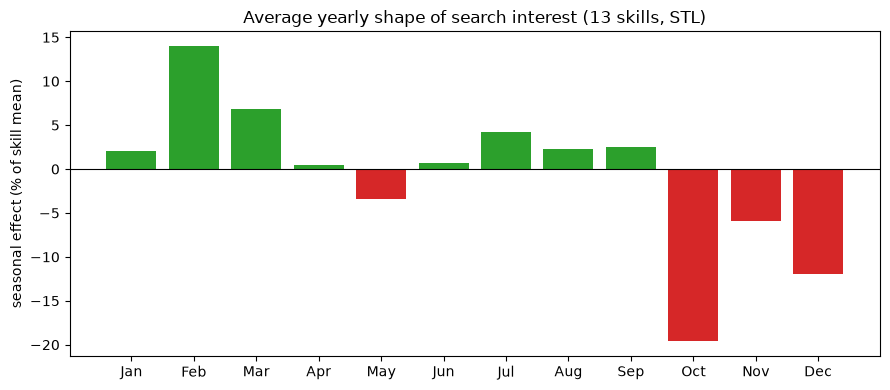

,skill,seasonal_strength,trend_strength
3,Docker,0.712,0.377
7,Git,0.656,0.696
5,AWS,0.637,0.569
1,Excel,0.624,0.767
10,React,0.616,0.927
6,Azure,0.611,0.773
13,JavaScript,0.577,0.937
11,SQL,0.577,0.928
0,Machine Learning,0.565,0.785
9,Linux,0.549,0.799


In [11]:
from statsmodels.tsa.seasonal import STL

rows = []
for s in reliable_skills:
    res = STL(monthly[s].astype(float), period=12, robust=True).fit()
    strength = lambda comp: max(0.0, 1 - res.resid.var() / (comp + res.resid).var())
    rows.append({'skill': s, 'seasonal_strength': round(strength(res.seasonal), 3),
                 'trend_strength': round(strength(res.trend), 3)})
stl_tbl = pd.DataFrame(rows).sort_values('seasonal_strength', ascending=False)
stl_tbl.to_csv(FIG / 'seasonality_strength.csv', index=False)
print(f'median seasonal strength = {stl_tbl["seasonal_strength"].median():.2f}, '
      f'median trend strength = {stl_tbl["trend_strength"].median():.2f}')

# Average yearly shape (% of each skill's own mean) for skills with a non-zero seasonal component.
seasonal_skills = stl_tbl.loc[stl_tbl['seasonal_strength'] > 0, 'skill']
profile = pd.DataFrame({
    s: (STL(monthly[s].astype(float), period=12, robust=True).fit().seasonal / monthly[s].mean() * 100)
       .groupby(monthly.index.month).mean() for s in seasonal_skills})
avg_profile = profile.mean(axis=1).round(1)
avg_profile.to_csv(FIG / 'seasonal_profile.csv', header=['pct_vs_skill_mean'])

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'], avg_profile.values,
       color=['tab:green' if v >= 0 else 'tab:red' for v in avg_profile.values])
ax.axhline(0, color='black', lw=0.8)
ax.set_ylabel('seasonal effect (% of skill mean)')
ax.set_title(f'Average yearly shape of search interest ({len(seasonal_skills)} skills, STL)')
plt.tight_layout()
fig.savefig(FIG / '06_seasonal_profile.png', dpi=120)
plt.show()
stl_tbl

## 4. Write the contract output `data/review2/skill_trends.csv`

This is the shared file Member C (combined insight) and Member D (dashboard) read.

In [12]:
out = trend_tbl.merge(label_check[['skill', 'mk_p', 'trend_confirmed']], on='skill')
out = out[['skill', 'slope_per_week', 'pct_change', 'class', 'low_volume', 'mk_p', 'trend_confirmed']]
out_path = ROOT / "data" / "review2" / "skill_trends.csv"
out.to_csv(out_path, index=False)
print(f"wrote {len(out)} skills -> {out_path.relative_to(ROOT)}")
print("reliable skills (not low volume):")
out.loc[~out["low_volume"], "class"].value_counts()

wrote 20 skills -> data\review2\skill_trends.csv
reliable skills (not low volume):


class
declining    8
stable       5
rising       1
Name: count, dtype: int64

## 5. Interpretation & limitations

**Data validation (2c):** the series are complete (261 regular weekly points, no gaps or missing values)
and the shared SQL anchor agrees across batches (min r = 0.999), so the rescaling is sound. Against the
earlier plain-word pull, 10 of 14 shared skills keep the same class (median r = 0.956). The four that
differ are explained: AWS sits on the ±10% cut-off (−10.0% vs −5.6%); Machine Learning, SAP and Spark are
ambiguous as plain words, which is why topic IDs were used.

**What the classification supports (14 skills that pass the data-quality flag, 11 confirmed by a
Mann-Kendall test, p < 0.05):**
- **Declining search interest, confirmed (6):** Python, SQL, Java, JavaScript, Linux, Git. These are also
  among the most-demanded skills in postings, so falling *search* interest here points to skills becoming
  baseline expectations (and to AI assistants replacing how-to searches), **not** to falling usage or
  hiring. Read as relative search interest, never as demand.
- **Rising, confirmed (1):** Machine Learning (+40% median) — the only reliable riser.
- **Stable, confirmed (4):** Excel, Power BI, Docker, AWS.
- **Not confirmed (3):** Azure and React are labelled declining by the first-year-vs-last-year rule but
  the Mann-Kendall test finds no monotone trend: both rose then fell (yearly medians Azure 10→14→10, React
  13→28→11), so an end-point comparison misdescribes them — we report them as *rose then fell*, not
  *declining*. SEO is "stable" by medians but the test finds a small upward drift (≈0.013/month on a
  flat, spike-driven series); we treat it as inconclusive. Only AWS and Azure change label if the cut-off
  moves between ±5% and ±20%.

**What it does not support:**
- **Not presented as findings (`low_volume`):** Deep Learning, Google Cloud, Kubernetes, Tableau, Spark,
  SAP. Their raw Google values are single digits, so a "−50%" is a one-or-two-point rounding change. Deep
  Learning and Google Cloud look "rising" but are in this group.
- **Two results we caught and corrected during analysis:** (1) AWS's company topic read ≈0 until mid-2022
  then jumped to ≈19, producing a fake "+103%"; we switched AWS to the plain term. (2) SEO's mean-based
  "+58%" came from one spike week (Dec 2025); its median change is 0%, so the classifier now uses medians.

**Forecasting — rolling-origin backtest (3c): 14 reliable skills × 7 origins = 98 three-month windows:**
- Mean MAPE: naïve 15.9, SES 15.7, ARIMA 17.8, Holt-Winters 21.1 (medians 10.7 / 10.6 / 11.1 / 12.2).
  No method beats naïve more than about half the time (0.49 / 0.51 / 0.48) and none differs significantly
  (Wilcoxon p = 0.88 / 0.80 / 0.40). Two further metrics agree: mean sMAPE 13.5 / 13.2 / 13.3 / 14.9, and
  mean MASE relative to naïve 1.00 / 0.97 / 1.05 / 1.19 (below 1 = better than naïve). SES is 3% better
  and not significant; ARIMA and Holt-Winters are worse. SEO (MAPE 80–131%) inflates the MAPE means;
  without it they are 10.9, 10.9, 11.0 and 12.6, the same ordering. The earlier single 6-month split on
  four skills is consistent with this (naïve wins Excel and Java, ARIMA wins Python by 0.08 and
  JavaScript by 1.6 MAPE points).
- **Conclusion:** short-horizon point forecasts of search interest add nothing measurable over "next value
  = last value". The dependable output of this method is the trend classification, not the forecast.
- **Seasonality (3d):** STL finds a moderate yearly pattern in-sample (median seasonal strength 0.58 vs
  trend strength 0.78): interest is ≈20% below a skill's average in October, 12% below in December and
  14% above in February. It does not translate into better forecasts (Holt-Winters is the worst model
  out of sample), and STL strength is optimistic on only ~5 cycles. We therefore report the pattern as
  descriptive; linking it to the academic or festival calendar is a hypothesis we did not test. This
  replaces our earlier claim that there is no seasonality.
- **Autocorrelation:** the Python ACF/PACF show a significant lag-1 term (≈ −0.35) and a second PACF
  spike, consistent with an ARIMA(1,1,x) structure; we did not tune the order.

**Scope & limits:** India, weekly, `today 5-y`; anchor `SQL`; query terms are Google topic IDs (AWS: plain
term). Google returns a sample of integer indices, so small series are coarse. The Mann-Kendall test uses
~60 monthly points and 14 skills are tested at once (no multiple-testing correction). Search interest is a
proxy for public attention only; no causal or lead-lag link to hiring is tested (postings cover about 3
months, too short for that).